# **Preprocessing & Exploratory Data Analysis**

This notebook preprocesses the data and conducts multivariate exploratory data analysis (EDA). We will then load a few example data points to demonstrate what the data looks like.

## **Data Setup & Quality Check**

In [3]:
# Import packages
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Download the dataset from Kaggle
path = kagglehub.dataset_download("dhrubangtalukdar/e-commerce-shopper-behavior-amazonshopify-based")
print("Path to dataset files:", path)
# print(list(Path(path).iterdir()))

Path to dataset files: /Users/mandyzhan/.cache/kagglehub/datasets/dhrubangtalukdar/e-commerce-shopper-behavior-amazonshopify-based/versions/1


In [4]:
csv_path = Path(path) / "e_commerce_shopper_behaviour_and_lifestyle.csv"
pd.set_option("display.max_columns", None)  # Display all 60 columns
df = pd.read_csv(csv_path)
df.head()

,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,household_size,occupation,ethnicity,language_preference,device_type,weekly_purchases,monthly_spend,cart_abandonment_rate,review_writing_frequency,average_order_value,preferred_payment_method,coupon_usage_frequency,loyalty_program_member,referral_count,product_category_preference,shopping_time_of_day,weekend_shopper,impulse_purchases_per_month,browse_to_buy_ratio,return_frequency,budgeting_style,brand_loyalty_score,impulse_buying_score,environmental_consciousness,health_conscious_shopping,travel_frequency,hobby_count,social_media_influence_score,reading_habits,exercise_frequency,stress_from_financial_decisions,overall_stress_level,sleep_quality,physical_activity_level,mental_health_score,daily_session_time_minutes,product_views_per_day,ad_views_per_day,ad_clicks_per_day,wishlist_items_count,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate
0,1,56,Female,Germany,Suburban,90860,Self-employed,Associate Degree,Single,0,5,Healthcare,Other,English,Mobile,4,2405,0,3,445,PayPal,3,1,8,Groceries,Morning,1,2,12,1,Strict,8,1,4,1,8,0,2,22,4,0,0,5,2,7,100,38,14,1,5,10,2,62,7,74,19,2025-06-22,6,1,50
1,2,69,Male,Japan,Suburban,35423,Unemployed,Bachelor,Single,1,2,Finance,Other,Mandarin,Mobile,13,3651,28,6,179,Google Pay,0,1,3,Groceries,Afternoon,1,3,93,12,Loose,4,3,7,1,4,1,5,14,4,4,5,9,8,5,28,19,9,2,17,5,7,54,5,23,8,2026-07-25,3,0,37
2,3,46,Female,India,Urban,21467,Self-employed,Associate Degree,Married,1,6,Healthcare,Other,Hindi,Mobile,10,2045,14,1,26,PayPal,0,0,10,Beauty,Afternoon,0,2,68,5,Moderate,2,2,5,1,6,2,0,14,4,0,0,8,10,10,61,38,1,4,18,3,3,33,7,12,13,2026-02-26,6,0,53
3,4,32,Male,Canada,Urban,41770,Self-employed,Bachelor,Widowed,0,4,Engineering,Hispanic,Hindi,Desktop,16,1611,11,2,403,Credit Card,2,1,0,Groceries,Afternoon,1,3,74,2,Moderate,3,2,0,1,12,1,1,15,0,2,0,9,2,1,78,35,9,2,8,5,9,26,4,19,9,2026-10-27,7,0,98
4,5,60,Female,Japan,Urban,183882,Employed,Associate Degree,Widowed,1,9,Other,Asian,English,Desktop,17,3476,57,3,68,Apple Pay,0,1,0,Groceries,Evening,0,6,34,12,Loose,7,8,9,0,6,5,10,20,5,8,10,5,3,2,27,50,16,0,10,8,0,18,7,30,3,2026-06-23,3,0,86


## **EDA: Explore & Summarize Data**

After importing the data, we further explore the data by using summary statistics and inspecting characteristics of the data.

In [5]:
# Inspect the data
print(df.shape)
print(df.info())
print(df.isna().sum())
print(df.duplicated().sum())

(1000000, 60)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 60 columns):
 #   Column                           Non-Null Count    Dtype 
---  ------                           --------------    ----- 
 0   user_id                          1000000 non-null  int64 
 1   age                              1000000 non-null  int64 
 2   gender                           1000000 non-null  object
 3   country                          1000000 non-null  object
 4   urban_rural                      1000000 non-null  object
 5   income_level                     1000000 non-null  int64 
 6   employment_status                1000000 non-null  object
 7   education_level                  1000000 non-null  object
 8   relationship_status              1000000 non-null  object
 9   has_children                     1000000 non-null  int64 
 10  household_size                   1000000 non-null  int64 
 11  occupation                       1000000 non-null 

Closer inspection of the data reveals that we do not have any missing values. Focusing on the column **last_purchase_date**, I decided to convert the str object to the number of days since the individual's last purchase. Determining how long it has been since an individual has purchased a product can be useful marketing and clustering information, as recent purchases are stronger indicators of an individual being a customer.

In [6]:
# Convert last_purchase_date from str to datetime, then from datetime to number of days
df["last_purchase_date"] = pd.to_datetime(df["last_purchase_date"], errors = "coerce")

# Sanity checks
print("Earliest:", df["last_purchase_date"].min())
print("Latest:", df["last_purchase_date"].max())
print("Unparseable:", df["last_purchase_date"].isna().sum())

# Select a date to reference against to compute date recency
reference_date = df["last_purchase_date"].max() + pd.Timedelta(days = 1) # Adds an extra
# day to the latest date so the newest customer is counted

# Create a column in the dataframe to hold number of days since last purchase, compared
# against the reference day
df["recency_days"] = (reference_date - df["last_purchase_date"]).dt.days
df["recency_days"].head()

Earliest: 2025-01-01 00:00:00
Latest: 2027-01-01 00:00:00
Unparseable: 0


0    559
1    161
2    310
3     67
4    193
Name: recency_days, dtype: int64

In [7]:
# Generate descriptive statistics summarizing the central tendency, dispersion, and shape of a dataset's distribution
df.describe()

,user_id,age,income_level,has_children,household_size,weekly_purchases,monthly_spend,cart_abandonment_rate,review_writing_frequency,average_order_value,coupon_usage_frequency,loyalty_program_member,referral_count,weekend_shopper,impulse_purchases_per_month,browse_to_buy_ratio,return_frequency,brand_loyalty_score,impulse_buying_score,environmental_consciousness,health_conscious_shopping,travel_frequency,hobby_count,social_media_influence_score,reading_habits,exercise_frequency,stress_from_financial_decisions,overall_stress_level,sleep_quality,physical_activity_level,mental_health_score,daily_session_time_minutes,product_views_per_day,ad_views_per_day,ad_clicks_per_day,wishlist_items_count,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate,recency_days
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,500000.500000,49.003377,104994.565463,0.399426,5.505323,9.993011,2498.775654,40.212257,3.450584,255.031632,2.002277,0.499818,5.004928,0.500035,3.290010,55.000136,6.000272,4.999277,4.998423,5.005931,0.500046,5.993844,2.499994,5.004101,11.995084,3.501375,4.998577,4.999507,6.498723,4.993603,5.002855,60.014414,25.018014,10.001036,2.498174,9.99766,5.494336,4.997523,50.001442,3.498840,49.989012,12.509560,2026-01-01 09:29:37.161600768,3.593763,0.359415,50.004949,365.604431
min,1.000000,18.000000,10000.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2025-01-01 00:00:00,0.000000,0.000000,0.000000,1.000000
25%,250000.750000,33.000000,57466.000000,0.000000,3.000000,5.000000,1249.000000,18.000000,2.000000,132.000000,1.000000,0.000000,2.000000,0.000000,2.000000,32.000000,3.000000,2.000000,2.000000,2.000000,0.000000,3.000000,1.000000,2.000000,6.000000,2.000000,2.000000,2.000000,5.000000,2.000000,2.000000,30.000000,12.000000,5.000000,1.000000,5.00000,3.000000,2.000000,25.000000,1.000000,25.000000,7.000000,2025-07-03 00:00:00,2.000000,0.000000,25.000000,183.000000
50%,500000.500000,49.000000,105013.000000,0.000000,6.000000,10.000000,2498.000000,40.000000,3.000000,255.000000,2.000000,0.000000,5.000000,1.000000,3.000000,55.000000,6.000000,5.000000,5.000000,5.000000,1.000000,6.000000,2.000000,5.000000,12.000000,4.000000,5.000000,5.000000,6.000000,5.000000,5.000000,60.000000,25.000000,10.000000,2.000000,10.00000,5.000000,5.000000,50.000000,3.000000,50.000000,13.000000,2026-01-02 00:00:00,4.000000,0.000000,50.000000,365.000000
75%,750000.250000,65.000000,152497.000000,1.000000,8.000000,15.000000,3750.000000,62.000000,5.000000,378.000000,3.000000,1.000000,8.000000,1.000000,5.000000,78.000000,9.000000,8.000000,8.000000,8.000000,1.000000,9.000000,4.000000,8.000000,18.000000,6.000000,8.000000,8.000000,8.000000,8.000000,8.000000,90.000000,38.000000,15.000000,4.000000,15.00000,8.000000,8.000000,75.000000,6.000000,75.000000,19.000000,2026-07-03 00:00:00,5.000000,1.000000,75.000000,548.000000
max,1000000.000000,80.000000,200000.000000,1.000000,1

In [8]:
# Convert text columns to category and downcast numerics to shrink the dataframe and reduce RAM usage
for col in df.select_dtypes("object"):
    df[col] = df[col].astype("category")
for col in df.select_dtypes("float64"):
    df[col] = pd.to_numeric(df[col], downcast = "float")
for col in df.select_dtypes("int64"):
    df[col] = pd.to_numeric(df[col], downcast = "integer")

print(f"{df.memory_usage(deep = True).sum() / 1e9:.2f} GB")

Path("../data/processed").mkdir(parents = True, exist_ok = True)
df.to_parquet("../data/processed/raw.parquet")

0.08 GB


In [9]:
# Verify the file exists since Parquet files are not UTF-8 encoded
check = pd.read_parquet("../data/processed/raw.parquet")
print(check.shape)
print(f"{check.memory_usage(deep=True).sum() / 1e9:.2f} GB")
check.dtypes.value_counts()
check.head()

(1000000, 61)
0.08 GB


,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,household_size,occupation,ethnicity,language_preference,device_type,weekly_purchases,monthly_spend,cart_abandonment_rate,review_writing_frequency,average_order_value,preferred_payment_method,coupon_usage_frequency,loyalty_program_member,referral_count,product_category_preference,shopping_time_of_day,weekend_shopper,impulse_purchases_per_month,browse_to_buy_ratio,return_frequency,budgeting_style,brand_loyalty_score,impulse_buying_score,environmental_consciousness,health_conscious_shopping,travel_frequency,hobby_count,social_media_influence_score,reading_habits,exercise_frequency,stress_from_financial_decisions,overall_stress_level,sleep_quality,physical_activity_level,mental_health_score,daily_session_time_minutes,product_views_per_day,ad_views_per_day,ad_clicks_per_day,wishlist_items_count,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate,recency_days
0,1,56,Female,Germany,Suburban,90860,Self-employed,Associate Degree,Single,0,5,Healthcare,Other,English,Mobile,4,2405,0,3,445,PayPal,3,1,8,Groceries,Morning,1,2,12,1,Strict,8,1,4,1,8,0,2,22,4,0,0,5,2,7,100,38,14,1,5,10,2,62,7,74,19,2025-06-22,6,1,50,559
1,2,69,Male,Japan,Suburban,35423,Unemployed,Bachelor,Single,1,2,Finance,Other,Mandarin,Mobile,13,3651,28,6,179,Google Pay,0,1,3,Groceries,Afternoon,1,3,93,12,Loose,4,3,7,1,4,1,5,14,4,4,5,9,8,5,28,19,9,2,17,5,7,54,5,23,8,2026-07-25,3,0,37,161
2,3,46,Female,India,Urban,21467,Self-employed,Associate Degree,Married,1,6,Healthcare,Other,Hindi,Mobile,10,2045,14,1,26,PayPal,0,0,10,Beauty,Afternoon,0,2,68,5,Moderate,2,2,5,1,6,2,0,14,4,0,0,8,10,10,61,38,1,4,18,3,3,33,7,12,13,2026-02-26,6,0,53,310
3,4,32,Male,Canada,Urban,41770,Self-employed,Bachelor,Widowed,0,4,Engineering,Hispanic,Hindi,Desktop,16,1611,11,2,403,Credit Card,2,1,0,Groceries,Afternoon,1,3,74,2,Moderate,3,2,0,1,12,1,1,15,0,2,0,9,2,1,78,35,9,2,8,5,9,26,4,19,9,2026-10-27,7,0,98,67
4,5,60,Female,Japan,Urban,183882,Employed,Associate Degree,Widowed,1,9,Other,Asian,English,Desktop,17,3476,57,3,68,Apple Pay,0,1,0,Groceries,Evening,0,6,34,12,Loose,7,8,9,0,6,5,10,20,5,8,10,5,3,2,27,50,16,0,10,8,0,18,7,30,3,2026-06-23,3,0,86,193


We identified and separated columns based on their attributes or uses. Each column was given a role defined below.

* **Cluster features**: Clusters are based on behavioral and attitudinal attributes, such as purchasing behavior and attitude scores.
* **Holdout**: Columns used for validating segments after training, including loyalty and subscription variables.
* **Profile**: Demographic attributes describing the segments to keep them behavioral.
* **Exclude**: Attributes with low marketing relevance and contain sensitive information that would not be acted on.
* **Drop**: Columns that were dropped as they only served to identify each data point. Kept only as an index for joining back later.

We go through each column and place them into a data dictionary with each column mapped to its role.

In [16]:
COLUMN_ROLES = {
    "user_id": "drop", 
    "age": "profile",
    "gender": "profile",
    "country": "profile",
    "urban_rural": "profile",
    "income_level": "profile",
    "employment_status": "profile",
    "education_level": "profile",
    "relationship_status": "profile",
    "has_children": "profile",
    "household_size": "profile",
    "occupation": "profile",
    "ethnicity": "profile",
    "language_preference": "profile",
    "device_type": "profile",
    "weekly_purchases": "cluster",
    "monthly_spend": "cluster",
    "cart_abandonment_rate": "cluster",
    "review_writing_frequency": "cluster",
    "average_order_value": "cluster",
    "preferred_payment_method": "profile",
    "coupon_usage_frequency": "cluster",
    "loyalty_program_member": "holdout",
    "referral_count": "cluster",
    "product_category_preference": "profile",
    "shopping_time_of_day": "profile",
    "weekend_shopper": "profile",
    "impulse_purchases_per_month": "cluster",
    "browse_to_buy_ratio": "cluster",
    "return_frequency": "exclude",
    "budgeting_style": "exclude",
    "brand_loyalty_score": "holdout",
    "impulse_buying_score": "cluster",
    "environmental_consciousness": "profile",
    "health_conscious_shopping": "profile",
    "travel_frequency": "exclude",
    "hobby_count": "exclude",
    "social_media_influence_score": "cluster",
    "reading_habits": "exclude",
    "exercise_frequency": "exclude",
    "stress_from_financial_decisions": "exclude",
    "overall_stress_level": "exclude",
    "sleep_quality": "exclude",
    "physical_activity_level": "exclude",
    "mental_health_score": "exclude",
    "daily_session_time_minutes": "cluster",
    "product_views_per_day": "cluster",
    "ad_views_per_day": "cluster",
    "ad_clicks_per_day": "cluster",
    "wishlist_items_count": "cluster",
    "cart_items_average": "cluster",
    "checkout_abandonments_per_month": "cluster",
    "purchase_conversion_rate": "cluster",
    "app_usage_frequency": "cluster",
    "notification_response_rate": "cluster",
    "account_age_months": "cluster",
    "last_purchase_date": "exclude",
    "social_sharing_frequency": "cluster",
    "premium_subscription": "holdout",
    "return_rate": "cluster",
    "recency_days": "cluster"
}

# Derive each feature from each column role
def columns(role):
    '''
    Derive features from COLUMN_ROLES based on its assigned role

    Params:
    role (str): Type of role assigned to the column in COLUMN_ROLES
    '''
    return [c for c, r in COLUMN_ROLES.items() if r == role]

print("CLUSTER:", columns("cluster"))
print("\nHOLDOUT:", columns("holdout"))
print("\nPROFILE:", columns("profile"))
print("\nEXCLUDE:", columns("exclude"))
print("\nDROP:", columns("drop"), "\n")

# Check if every role is valid
VALID_ROLES = {"cluster", "holdout", "profile", "exclude", "drop"}
print({c: r for c, r in COLUMN_ROLES.items() if r not in VALID_ROLES}, "\n")  # Should return empty

# Check that every column in the dataset appears in COLUMN_ROLES
print(set(df.columns) - set(COLUMN_ROLES))  # Returns empty if every column has a role
print(set(COLUMN_ROLES) - set(df.columns))  # Returns empty if every dict entry exists
# in the data

CLUSTER: ['weekly_purchases', 'monthly_spend', 'cart_abandonment_rate', 'review_writing_frequency', 'average_order_value', 'coupon_usage_frequency', 'referral_count', 'impulse_purchases_per_month', 'browse_to_buy_ratio', 'impulse_buying_score', 'social_media_influence_score', 'daily_session_time_minutes', 'product_views_per_day', 'ad_views_per_day', 'ad_clicks_per_day', 'wishlist_items_count', 'cart_items_average', 'checkout_abandonments_per_month', 'purchase_conversion_rate', 'app_usage_frequency', 'notification_response_rate', 'account_age_months', 'social_sharing_frequency', 'return_rate', 'recency_days']

HOLDOUT: ['loyalty_program_member', 'brand_loyalty_score', 'premium_subscription']

PROFILE: ['age', 'gender', 'country', 'urban_rural', 'income_level', 'employment_status', 'education_level', 'relationship_status', 'has_children', 'household_size', 'occupation', 'ethnicity', 'language_preference', 'device_type', 'preferred_payment_method', 'product_category_preference', 'shopping

## **EDA: Visualizing Data**

Now that we have explored and summarized the data, we move on to visualizing our data. Using all one million data points is slow and difficult to visualize, so we will use a random sample of 100K points in hopes of boosting performance, simplifying data visualization, and provide a quick overview of our data.

In [36]:
# Use a random sample of 100K data points
sample = df.sample(n = 100000, random_state = 42)

browse_to_buy_ratio               -0.007718
ad_views_per_day                  -0.005871
referral_count                    -0.005649
coupon_usage_frequency            -0.005183
social_media_influence_score      -0.003194
notification_response_rate        -0.002259
monthly_spend                     -0.000754
impulse_buying_score              -0.000246
recency_days                       0.000295
ad_clicks_per_day                  0.000603
product_views_per_day              0.001202
checkout_abandonments_per_month    0.001665
account_age_months                 0.003366
daily_session_time_minutes         0.003468
app_usage_frequency                0.003634
wishlist_items_count               0.004692
return_rate                        0.006844
cart_items_average                 0.007110
purchase_conversion_rate           0.007459
average_order_value                0.007477
weekly_purchases                   0.007882
social_sharing_frequency           0.025271
cart_abandonment_rate           

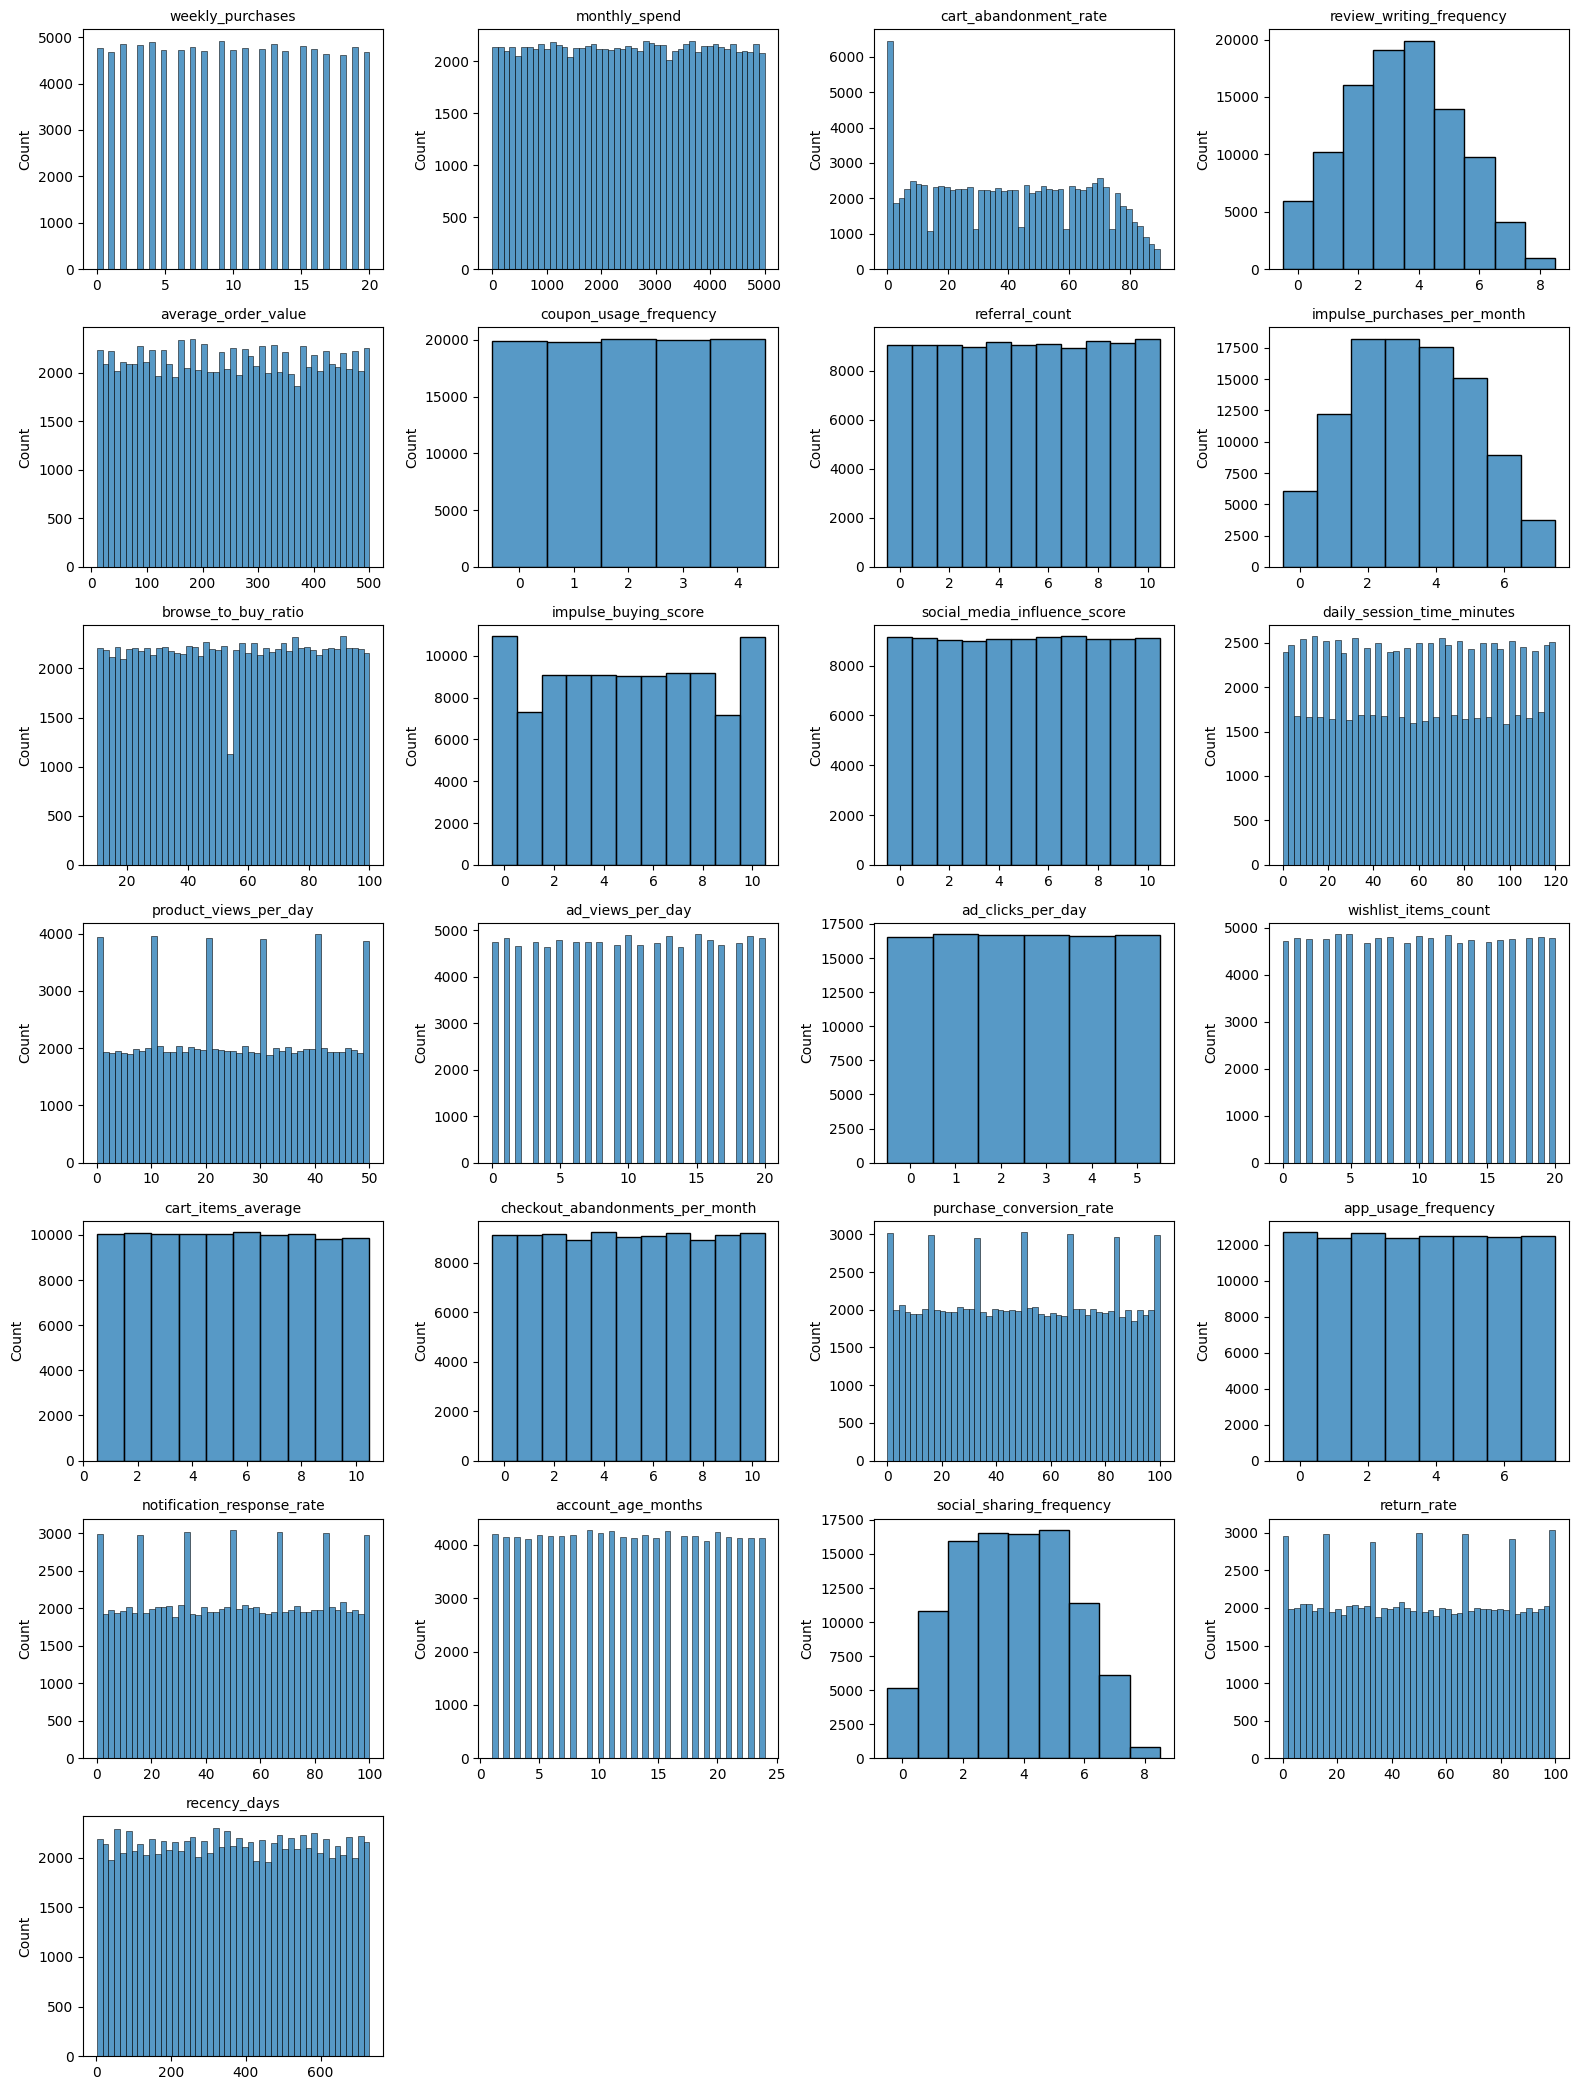

In [37]:
# Check feature distribution and skew
features = columns("cluster")

print(sample[features].skew().sort_values())  # Sorted overview of columns and potential
# skew

n_cols = 4
n_rows = -(-len(features) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize = (16, 3 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, features):
    is_discrete = sample[col].nunique() <= 15
    sns.histplot(sample[col], discrete=is_discrete,
                 bins = "auto" if not is_discrete else None, ax = ax)
    ax.set_title(col, fontsize = 10)
    ax.set_xlabel("")

for ax in axes[len(features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Most of the features are uniform with roughly equal counts across the whole range, which is to be expected from a randomly generated sample. For the feature **cart_abandonment_rate**, we notice that there is a sharp spike around 0. This may be due to how the feature was generated. Some features demonstrate a bell-shaped curve, such as **review_writing_frequency** and **impulse_purchases_per_month**, although it is worth noting that the scale is small.

In [38]:
# Check if features may be correlated
correlations = sample[features].corr()
print(correlations)  # Correlations between cluster feature
mask = np.triu(np.ones_like(correlations, dtype = bool))  # Hide the redundant upper triangle

# Strongest pairs, ranked
pairs = (sample[features].corr()).where(~mask).stack().abs().sort_values(ascending = False)
pairs.head(10)

                                 weekly_purchases  monthly_spend  \
weekly_purchases                         1.000000       0.001855   
monthly_spend                            0.001855       1.000000   
cart_abandonment_rate                    0.000338      -0.003763   
review_writing_frequency                 0.003218      -0.003727   
average_order_value                     -0.002329      -0.001605   
coupon_usage_frequency                  -0.000205      -0.002199   
referral_count                          -0.000167      -0.006752   
impulse_purchases_per_month             -0.000071      -0.004292   
browse_to_buy_ratio                     -0.000352       0.003560   
impulse_buying_score                     0.000525      -0.002421   
social_media_influence_score             0.003964       0.000830   
daily_session_time_minutes               0.003176       0.002809   
product_views_per_day                   -0.004114      -0.000272   
ad_views_per_day                        -0.00013

impulse_buying_score         cart_abandonment_rate           0.961303
                             impulse_purchases_per_month     0.883316
impulse_purchases_per_month  cart_abandonment_rate           0.849933
app_usage_frequency          ad_clicks_per_day               0.009391
purchase_conversion_rate     cart_items_average              0.008939
social_sharing_frequency     social_media_influence_score    0.008906
app_usage_frequency          cart_items_average              0.008719
return_rate                  impulse_buying_score            0.008282
notification_response_rate   cart_items_average              0.007955
return_rate                  cart_abandonment_rate           0.007809
dtype: float64

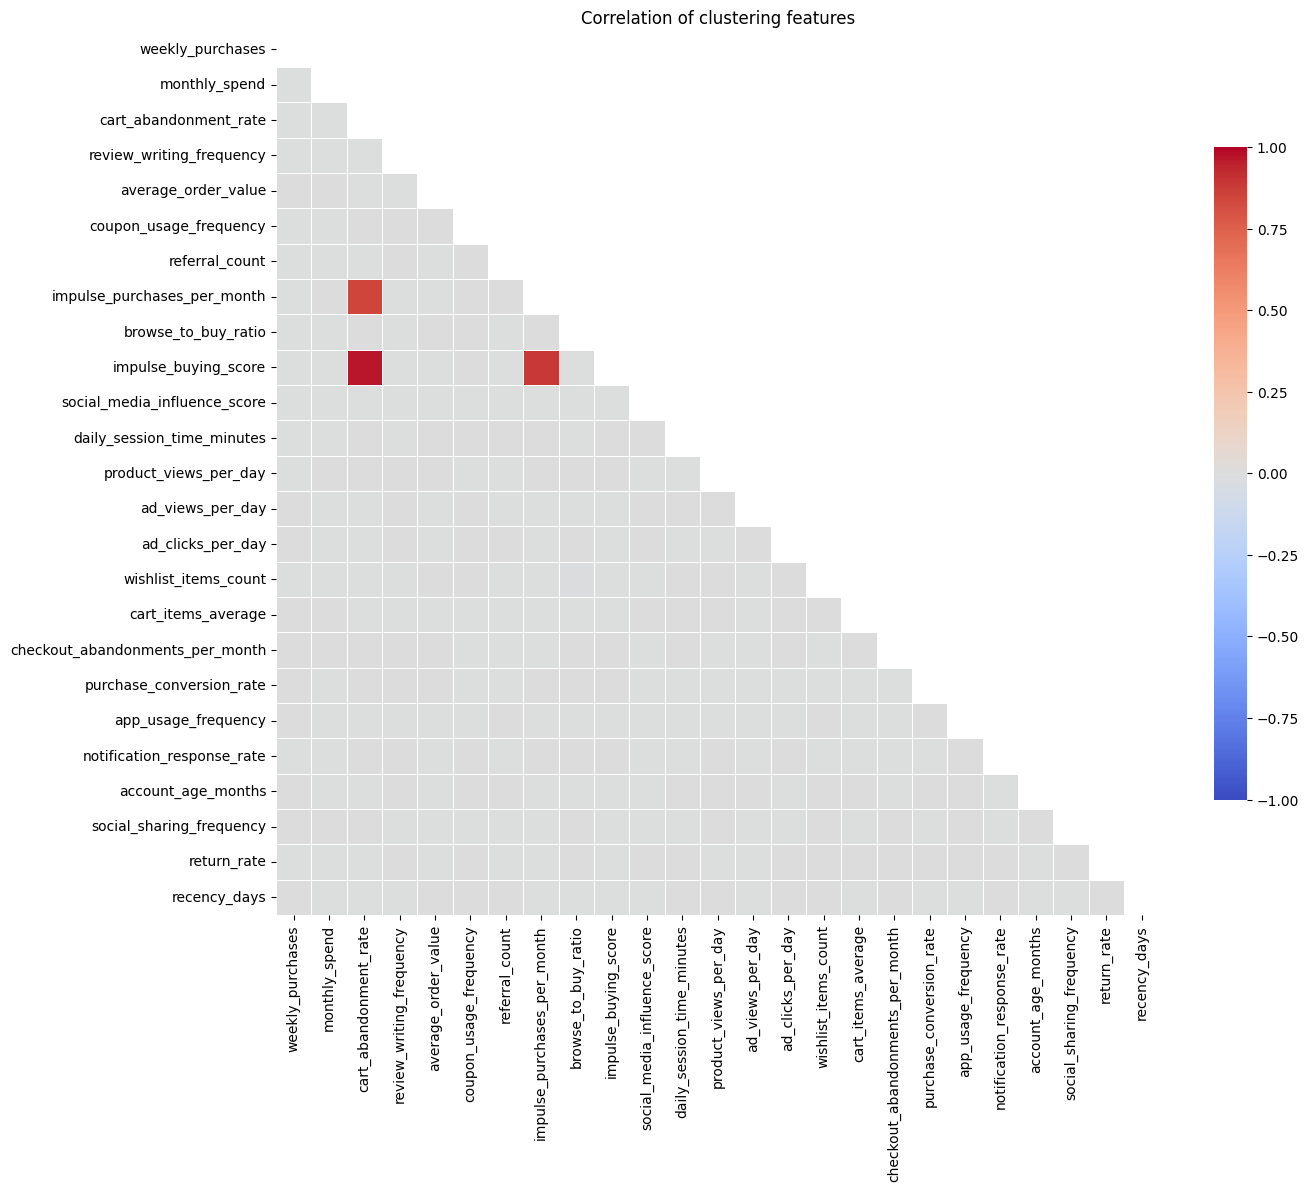

In [39]:
plt.figure(figsize = (14, 12))
sns.heatmap(corr, mask = mask, cmap = "coolwarm", center = 0, vmin = -1, vmax = 1,
            square = True, linewidths = 0.5, cbar_kws = {"shrink": 0.7})
plt.title("Correlation of clustering features")
plt.tight_layout()
plt.show()

From the correlation matrix and heatmap, most features are not correlated. Interestingly, **cart_abandonment_rate**, **impulse_buying_score** and **impulse_purchases_per_month** show strong, positive correlations with each other. **cart_abandonment_rate** had strong correlations with both features relating to impulsive behavior, with a coefficient of 0.961 with **impulse_buying_score** and 0.849 with **impulse_purchases_per_month**. The two impulsive-related features also had strong correlations with each other, demonstrating a coefficient of around 0.883. I anticipated strong correlation between similar features, but only the features about impulsive behavior met my expectation (0.883). Our dataset contains two features relating to ad experiences and another two about social media behavior, but the correlation between the related features was nearly nonexistent. Three strongly correlated features make impulsiveness about three times as influential as any single feature.

It is worth noting that a coefficient of 0.961 is unusually high, surpassing the coefficient of the two impulsive-related features. We create a scatter plot to further explore this outlier.

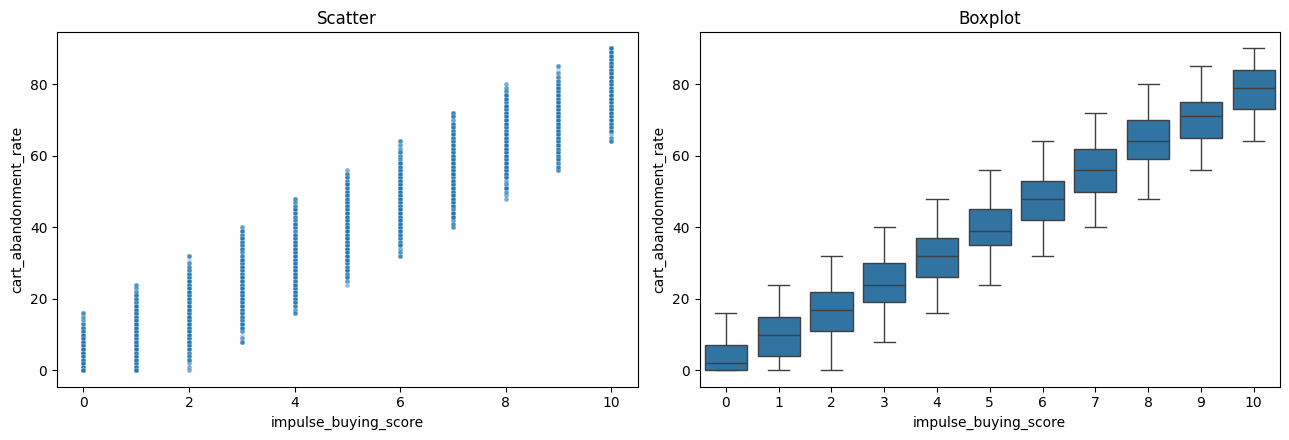

In [57]:
# Use a sample of 5K instead to prevent overplotting
small = sample.sample(5000, random_state = 42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Create a scatterplot of card_abandonment_rate and impulse_buying_score
sns.scatterplot(data = small, x = "impulse_buying_score", y = "cart_abandonment_rate", alpha = 0.25, s = 12, ax = axes[0])
axes[0].set_title("Scatter")

# Because y is discrete, a boxplot may be cleaner and can unpack the info from the scatterplot
sns.boxplot(data = small, x = "impulse_buying_score", y = "cart_abandonment_rate", ax = axes[1])
axes[1].set_title("Boxplot")

plt.tight_layout()
plt.show()

There are no clear outliers across both plots. For the boxplot specifically, the medians rise steadily and the boxes are roughly the same height. The data is neither tightly clustered (as would be demonstrated by short boxes) nor widely spread out (as would be demonstrated by tall boxes). However, the low extreme and whisker for the first box at impulse_buying_score = 0 is cut off. The spike at 0, as demonstrated in the histogram for **cart_abandonment_rate**, may come from values being clipped at a valid minimum. Zeroes are concentrated at low impulse scores, which suggests the feature was generated from that feature plus noise.

In [60]:
print(sample.groupby("impulse_buying_score")["cart_abandonment_rate"].agg(["min", "max", "mean"]))
print(sample.groupby("impulse_purchases_per_month")["cart_abandonment_rate"].agg(["min", "max", "mean"]))

                      min  max       mean
impulse_buying_score                     
0                       0   16   3.835530
1                       0   24   9.674151
2                       0   32  16.070767
3                       8   40  23.965153
4                      16   48  31.987589
5                      24   56  40.147705
6                      32   64  48.009074
7                      40   72  56.009923
8                      48   80  64.172294
9                      56   85  70.566564
10                     64   90  78.041751
                             min  max       mean
impulse_purchases_per_month                     
0                              0   24   6.139550
1                              0   40  13.169540
2                              0   56  20.691308
3                              0   72  36.134742
4                             16   85  51.294530
5                             32   90  63.709371
6                             48   90  71.418387
7            

In [ ]:
# TODO
# Run PCA
# Average cart_abandonment_rate w/ impulsive-related features to build an "impulsiveness"
# score